# Notebook 03 — Final 10-fold CNN training

This is the single planned CNN training experiment. Each fold gets its own normalization statistics, fitted only on that fold's training data. CNN training uses original and augmented training WAVs, but each original recording has equal total training weight. Fold validation metrics are calculated on original WAVs only.

After cross-validation, the final CNN is trained on the complete outer training partition and evaluated once on original recordings from the 11 held-out speakers.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

SEED = 42
EPOCHS = 60
BATCH_SIZE = 32
OUT = Path("anu_revision_output")
np.random.seed(SEED)
tf.random.set_seed(SEED)

data = np.load(OUT / "speaker_split_mfcc_10fold_raw.npz", allow_pickle=True)
X_raw = data["X_train_raw"]
X_test_raw = data["X_test_raw"]
y = data["y_train"]
y_test_all = data["y_test"]
fold_id = data["fold_id"]
train_source = data["train_original_ids"].astype(str)
test_source = data["test_original_ids"].astype(str)
train_is_original = data["train_is_original"].astype(bool)
test_is_original = data["test_is_original"].astype(bool)
classes = data["classes"].astype(str)

# Primary final-test evaluation uses only original test recordings.
X_test_original_raw = X_test_raw[test_is_original]
y_test = y_test_all[test_is_original]

print("Training WAVs:", len(y))
print("Original held-out test recordings:", len(y_test))
print("Cross-validation folds:", len(np.unique(fold_id)))

Training WAVs: 3522
Original held-out test recordings: 153
Cross-validation folds: 10


In [2]:
def normalize_from_fit(X_fit_raw, X_other_raw):
    # Fit statistics on training data only; apply unchanged to validation/test.
    mean = float(X_fit_raw.mean())
    std = float(X_fit_raw.std() + 1e-6)
    X_fit = ((X_fit_raw - mean) / std)[..., None]
    X_other = ((X_other_raw - mean) / std)[..., None]
    return X_fit.astype(np.float32), X_other.astype(np.float32), mean, std


def source_balanced_weights(source_ids):
    # Each original recording contributes equal total weight, regardless of
    # how many augmented derivatives it has in this training partition.
    _, inverse, counts = np.unique(
        source_ids, return_inverse=True, return_counts=True
    )
    weights = 1.0 / counts[inverse]
    weights = weights * (len(weights) / weights.sum())
    return weights.astype(np.float32)


def build_cnn(input_shape, n_classes):
    reg = tf.keras.regularizers.l2(1e-4)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),

        tf.keras.layers.Conv2D(32, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(64, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(128, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),

        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(128, activation="relu", kernel_regularizer=reg),
        tf.keras.layers.Dropout(0.35),
        tf.keras.layers.Dense(n_classes, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=8, restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6
        )
    ]


def metrics_dict(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro precision": p,
        "Macro recall": r,
        "Macro F1": f
    }

In [3]:
# Ten-fold cross-validation.
fold_rows = []
fold_best_epochs = []
fold_histories = []

for fold in range(1, 11):
    print(f"\\n========== FOLD {fold}/10 ==========")

    fit_mask = fold_id != fold
    val_mask_all = fold_id == fold

    # Train on all training-fold WAVs (original + augmented).
    X_fit_raw = X_raw[fit_mask]
    y_fit = y[fit_mask]
    fit_sources = train_source[fit_mask]

    # Validate on original WAVs only from the held-out speaker fold.
    val_mask = val_mask_all & train_is_original
    X_val_raw = X_raw[val_mask]
    y_val = y[val_mask]

    X_fit, X_val, fold_mean, fold_std = normalize_from_fit(
        X_fit_raw, X_val_raw
    )
    sample_weights = source_balanced_weights(fit_sources)

    model = build_cnn(X_fit.shape[1:], len(classes))
    history = model.fit(
        X_fit,
        y_fit,
        sample_weight=sample_weights,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks(),
        shuffle=True,
        verbose=1
    )

    val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
    fold_metrics = metrics_dict(y_val, val_pred)
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

    fold_rows.append({
        "Fold": fold,
        "Validation speakers": len(set(
            pd.read_csv(OUT / "train_manifest_10fold.csv")
            .loc[val_mask, "speaker_id"]
        )),
        "Validation original recordings": len(y_val),
        "Best epoch": best_epoch,
        **fold_metrics
    })
    fold_best_epochs.append(best_epoch)
    fold_histories.append(history.history)

    print("Fold metrics:", fold_metrics)
    tf.keras.backend.clear_session()

fold_results = pd.DataFrame(fold_rows)
display(fold_results)
fold_results.to_csv(OUT / "cnn_10fold_original_validation_results.csv", index=False)

summary = fold_results[
    ["Accuracy", "Macro precision", "Macro recall", "Macro F1"]
].agg(["mean", "std"]).T
display(summary)
summary.to_csv(OUT / "cnn_10fold_original_validation_summary.csv")

final_epochs = max(1, int(np.median(fold_best_epochs)))
print("Median best epoch used for final fit:", final_epochs)

\n========== FOLD 1/10 ==========
Epoch 1/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.1002 - loss: 2.6732 - val_accuracy: 0.0690 - val_loss: 2.6606 - learning_rate: 1.0000e-04
Epoch 2/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.1484 - loss: 2.5665 - val_accuracy: 0.1034 - val_loss: 2.6478 - learning_rate: 1.0000e-04
Epoch 3/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.1903 - loss: 2.4894 - val_accuracy: 0.1552 - val_loss: 2.6123 - learning_rate: 1.0000e-04
Epoch 4/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.2193 - loss: 2.3984 - val_accuracy: 0.2931 - val_loss: 2.5476 - learning_rate: 1.0000e-04
Epoch 5/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.2678 - loss: 2.3100 - val_accuracy: 0.2931 - val_loss: 2.4407 - learning_rate: 1.0000e-04
Epoch 6/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.3125 - loss: 2.2213 - val_accuracy: 0.3276 - val_loss: 2.3450 - learning_rate: 1.0000e-04
Epoch 7/60
100/100 ━━━━━

,Fold,Validation speakers,Validation original recordings,Best epoch,Accuracy,Macro precision,Macro recall,Macro F1
0,1,4,58,41,0.448276,0.591558,0.453571,0.460101
1,2,5,69,48,0.463768,0.542197,0.460714,0.461559
2,3,4,55,40,0.472727,0.494898,0.476190,0.464925
3,4,4,55,53,0.709091,0.729762,0.714286,0.709524
4,5,4,57,54,0.701754,0.732143,0.703571,0.700242
5,6,4,55,53,0.418182,0.529762,0.416667,0.421655
6,7,4,57,37,0.596491,0.608627,0.596429,0.563678
7,8,5,69,28,0.434783,0.532267,0.435714,0.425947
8,9,4,56,30,0.375000,0.491504,0.375000,0.377664
9,10,4,56,40,0.517857,0.512755,0.517857,0.483215


,mean,std
Accuracy,0.513793,0.117121
Macro precision,0.576547,0.089590
Macro recall,0.515000,0.118178
Macro F1,0.506851,0.114868


Median best epoch used for final fit: 40


In [4]:
# Final fit: all 42 outer-training speakers. No validation/test data used for fitting normalization.
X_final, X_test_original, final_mean, final_std = normalize_from_fit(
    X_raw, X_test_original_raw
)
final_weights = source_balanced_weights(train_source)

final_model = build_cnn(X_final.shape[1:], len(classes))
final_model.fit(
    X_final,
    y,
    sample_weight=final_weights,
    epochs=final_epochs,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=1
)

test_prob = final_model.predict(X_test_original, verbose=0)
test_pred = test_prob.argmax(axis=1)
final_test_metrics = metrics_dict(y_test, test_pred)

print("FINAL ORIGINAL-RECORDING TEST METRICS")
for key, value in final_test_metrics.items():
    print(f"{key}: {value:.4f}")

print(classification_report(
    y_test, test_pred, target_names=classes, zero_division=0
))

Epoch 1/40
111/111 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.0940 - loss: 2.6539
Epoch 2/40
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.1633 - loss: 2.5367
Epoch 3/40
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.2073 - loss: 2.4332
Epoch 4/40
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.2470 - loss: 2.3454
Epoch 5/40
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.2845 - loss: 2.2596
Epoch 6/40
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.3095 - loss: 2.1744
Epoch 7/40
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.3384 - loss: 2.0881
Epoch 8/40
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.3648 - loss: 2.0205
Epoch 9/40
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.3839 - loss: 1.9441
Epoch 10/40
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.4143 - loss: 1.8836
Epoch 11/40
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.4267 - loss: 1.8229
Epoch 12/40
111/111 ━━━━━━━━━━━━━━━━━━━━ 

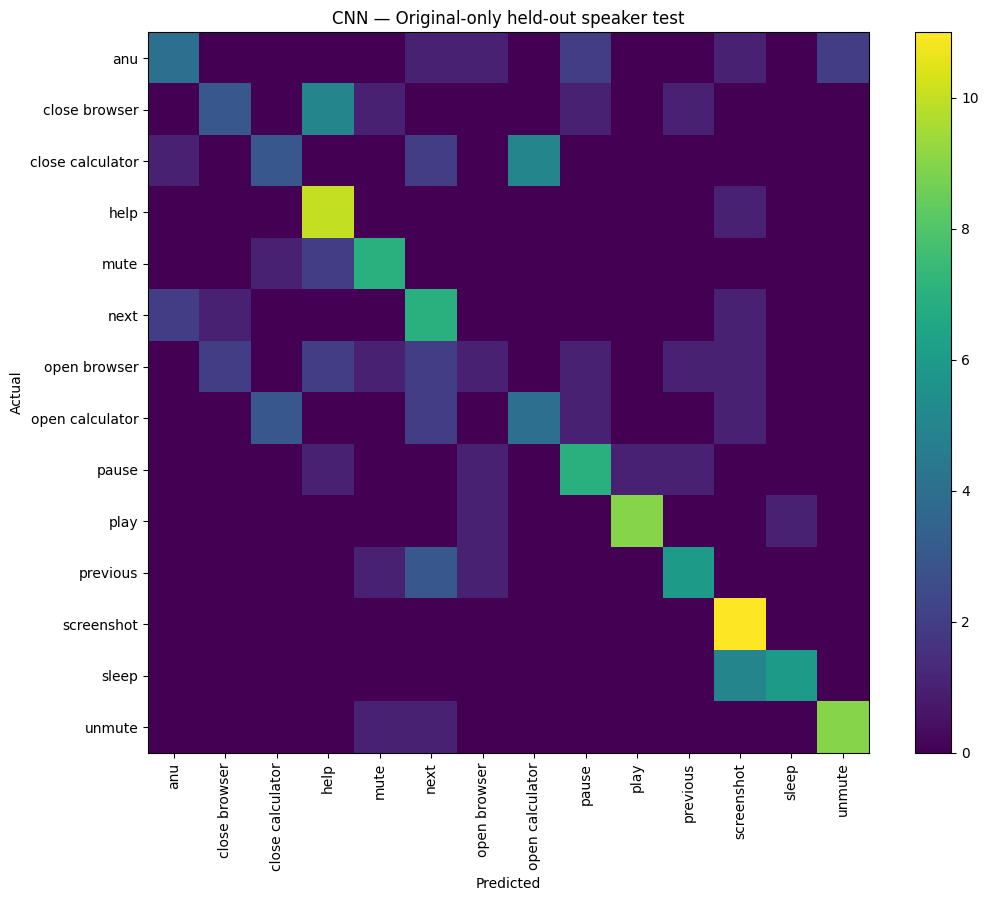

Final outputs saved in: C:\Users\ADMIN\Desktop\Sukriti\VIT\SL\AnuAssistant\Anu_Revision_Notebooks\anu_revision_output


In [6]:
# Save final model, preprocessing parameters, original-only predictions and confusion matrix.
final_model.save(OUT / "anu_cnn_final_10fold.keras")

pd.DataFrame({
    "true": classes[y_test],
    "predicted": classes[test_pred]
}).to_csv(OUT / "cnn_10fold_final_original_test_predictions.csv", index=False)

pd.DataFrame([{
    **final_test_metrics,
    "Test original recordings": len(y_test),
    "Final training epochs": final_epochs,
    "Normalization mean": final_mean,
    "Normalization std": final_std
}]).to_csv(OUT / "cnn_10fold_final_original_test_metrics.csv", index=False)

cm = confusion_matrix(y_test, test_pred)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm)
ax.set_xticks(range(len(classes)), classes, rotation=90)
ax.set_yticks(range(len(classes)), classes)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("CNN — Original-only held-out speaker test")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(OUT / "cnn_10fold_final_original_confusion_matrix.png", dpi=200)
plt.show()

history_rows = []
for fold, hist in enumerate(fold_histories, start=1):
    for i in range(len(hist["loss"])):
        history_rows.append({
            "Fold": fold, "Epoch": i + 1,
            "Loss": hist["loss"][i],
            "Accuracy": hist["accuracy"][i],
            "Validation loss": hist["val_loss"][i],
            "Validation accuracy": hist["val_accuracy"][i]
        })
pd.DataFrame(history_rows).to_csv(
    OUT / "cnn_10fold_training_histories.csv", index=False
)

print("Final outputs saved in:", OUT.resolve())